In [3]:
import pandas as pd
import numpy as np

def create_sliding_windows(df, window_size=100, step_size=50):
    features = []
    labels = []

    # Group by session so windows never blend different recordings
    for session_id, session_data in df.groupby('session_id'):
        # Extract the numerical sensor data
        sensor_values = session_data[['accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z']].values

        # Grab the activity label (assuming it is constant throughout the session)
        activity_label = session_data['label'].iloc[0]

        # Slide the window across the session array
        for start_idx in range(0, len(sensor_values) - window_size + 1, step_size):
            end_idx = start_idx + window_size
            window = sensor_values[start_idx:end_idx]

            features.append(window)
            labels.append(activity_label)

    return np.array(features), np.array(labels)

# 1. Load the uploaded file (Update the path to match your Drive folder)
file_path = 'sensor_data_augmented.csv'
df = pd.read_csv(file_path)

# 2. Generate the overlapping windows
X, y = create_sliding_windows(df, window_size=100, step_size=50)

print(f"Feature matrix shape (X): {X.shape}")
print(f"Labels shape (y): {y.shape}")

Feature matrix shape (X): (885, 100, 6)
Labels shape (y): (885,)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# 1. Convert string labels (e.g., 'Normal_Walking') to integers
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# 2. Convert integers to one-hot encoded vectors (required for multi-class classification)
y_categorical = to_categorical(y_encoded)

# 3. Split the data (80% for training, 20% for testing)
# Using stratify ensures every class is represented equally in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical
)

print(f"Training features: {X_train.shape}")
print(f"Testing features: {X_test.shape}")
print(f"Classes detected: {len(encoder.classes_)}")
print(f"Class mapping: {dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))}")

Training features: (708, 100, 6)
Testing features: (177, 100, 6)
Classes detected: 12
Class mapping: {np.str_('Abnormal_Fall'): np.int64(0), np.str_('Normal_Jumping'): np.int64(1), np.str_('Normal_Running'): np.int64(2), np.str_('Normal_Sitting'): np.int64(3), np.str_('Normal_Stairs_Down'): np.int64(4), np.str_('Normal_Stairs_Up'): np.int64(5), np.str_('Normal_Standing'): np.int64(6), np.str_('Normal_Walking'): np.int64(7), np.str_('Theft_Bag_Grab'): np.int64(8), np.str_('Theft_Hand_Snatch'): np.int64(9), np.str_('Theft_Pocket_Snatch'): np.int64(10), np.str_('Theft_Running_Away'): np.int64(11)}


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# 1. Define the LSTM Architecture
model = Sequential([
    # First LSTM layer reading the (100, 6) windows
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    Dropout(0.5), # Prevents overfitting by randomly turning off neurons

    # Second LSTM layer to extract deeper temporal features
    LSTM(32, return_sequences=False),
    Dropout(0.5),

    # Fully connected layers to interpret the LSTM outputs
    Dense(32, activation='relu'),
    Dense(12, activation='softmax') # 12 output nodes matching your classes
])

# 2. Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 3. Train the model
print("\n--- Starting Training ---")
history = model.fit(
    X_train, y_train,
    epochs=40,
    batch_size=32,
    validation_data=(X_test, y_test)
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 64)        │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           396 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,044 (125.17 KB)

 Trainable params: 32,044 (125.17 KB)

 Non-trainable params: 0 (0.00 B)


--- Starting Training ---
Epoch 1/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 118ms/step - accuracy: 0.1427 - loss: 2.4337 - val_accuracy: 0.2034 - val_loss: 2.3272
Epoch 2/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.2133 - loss: 2.2729 - val_accuracy: 0.2373 - val_loss: 2.1778
Epoch 3/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.2853 - loss: 2.0795 - val_accuracy: 0.3333 - val_loss: 1.9814
Epoch 4/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.3531 - loss: 1.8957 - val_accuracy: 0.3785 - val_loss: 1.8386
Epoch 5/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step - accuracy: 0.3743 - loss: 1.7811 - val_accuracy: 0.4463 - val_loss: 1.7457
Epoch 6/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.4364 - loss: 1.6568 - val_accuracy: 0.4746 - val_loss: 1.5603
Epoch 7/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - accuracy: 0.4929 - loss: 1.5315 - val_accuracy: 0.5537 - val_loss: 1.4210
Epoch 8/40
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - accuracy: 0.5141 - loss: 1.4

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step


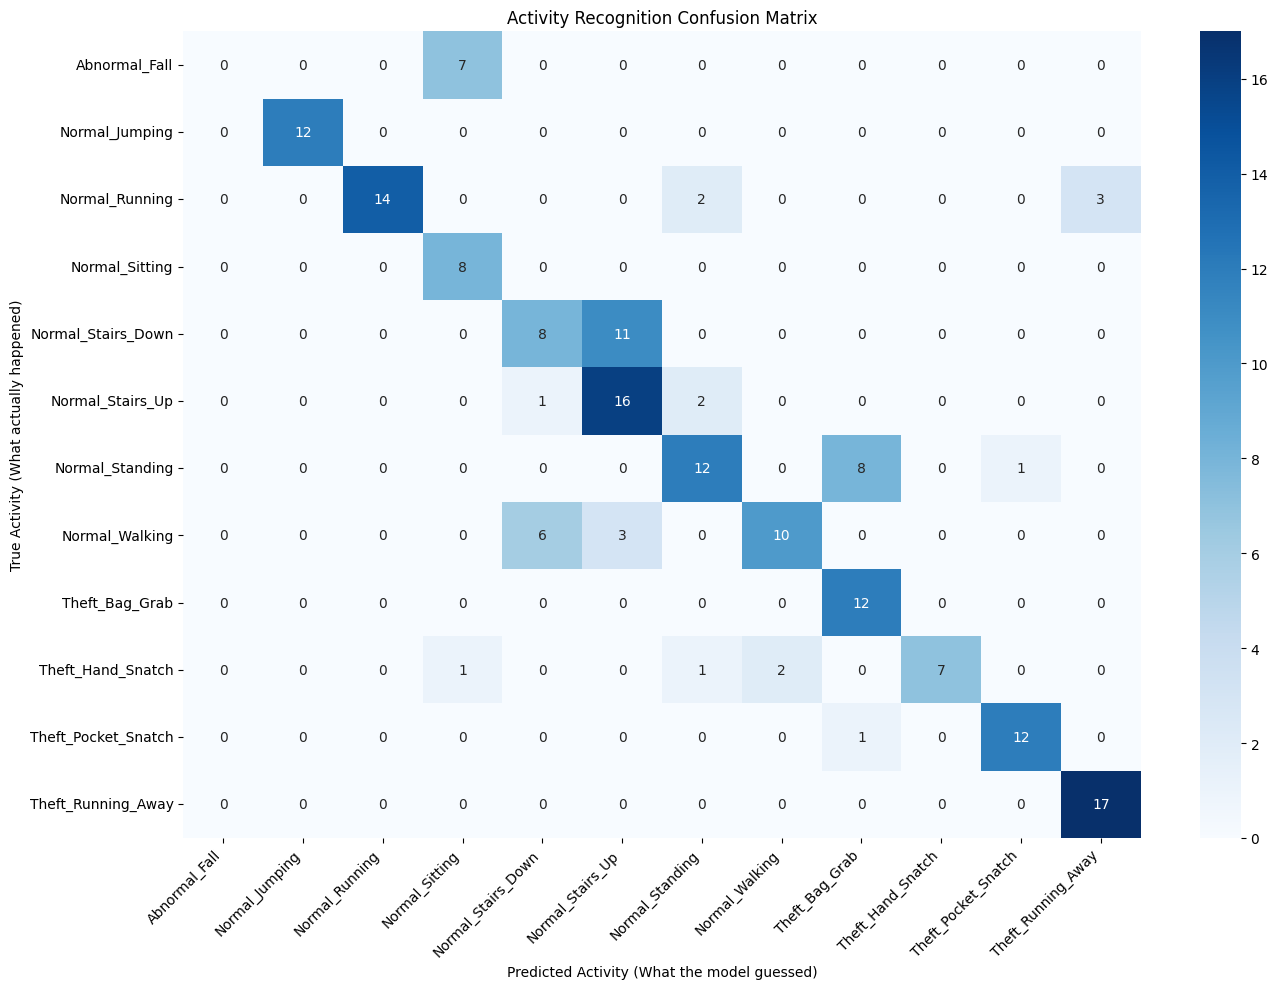

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Get the model's predictions on the unseen test set
y_pred = model.predict(X_test)

# 2. Convert predictions and true labels from one-hot encoding back to integers
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 3. Generate the raw confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# 4. Plot the matrix using Seaborn
plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)
plt.title('Activity Recognition Confusion Matrix')
plt.ylabel('True Activity (What actually happened)')
plt.xlabel('Predicted Activity (What the model guessed)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [7]:
# 1. Generate tighter windows (1 second duration, 0.5 second overlap)
X, y = create_sliding_windows(df, window_size=50, step_size=25)
print(f"New Feature matrix shape (X): {X.shape}")

# 2. Encode and split the new arrays
y_encoded = encoder.fit_transform(y)
y_categorical = to_categorical(y_encoded)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_categorical
)

# 3. Rebuild the LSTM for the smaller input shape
model = Sequential([
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    Dropout(0.5),
    LSTM(32, return_sequences=False),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(12, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Train the updated model
print("\n--- Starting Training on 1-Second Windows ---")
history = model.fit(
    X_train, y_train,
    epochs=40,
    batch_size=32,
    validation_data=(X_test, y_test)
)

New Feature matrix shape (X): (1938, 50, 6)

--- Starting Training on 1-Second Windows ---
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.1742 - loss: 2.4037 - val_accuracy: 0.2732 - val_loss: 2.2218
Epoch 2/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.3065 - loss: 2.0867 - val_accuracy: 0.3660 - val_loss: 1.8171
Epoch 3/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.4200 - loss: 1.7301 - val_accuracy: 0.4794 - val_loss: 1.5091
Epoch 4/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.4652 - loss: 1.4846 - val_accuracy: 0.5464 - val_loss: 1.2627
Epoch 5/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.5303 - loss: 1.3065 - val_accuracy: 0.5954 - val_loss: 1.0897
Epoch 6/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.5587 - loss: 1.1750 - val_accuracy: 0.6082 - val_loss: 1.0888
Epoch 7/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.5961 - loss: 1.0869 - val_accuracy: 0.6649 - val_loss: 0.9702
Epoch 8/40
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.6129 - loss: 0.9941 - val_accuracy: 0.6933 - val_loss: 0.

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


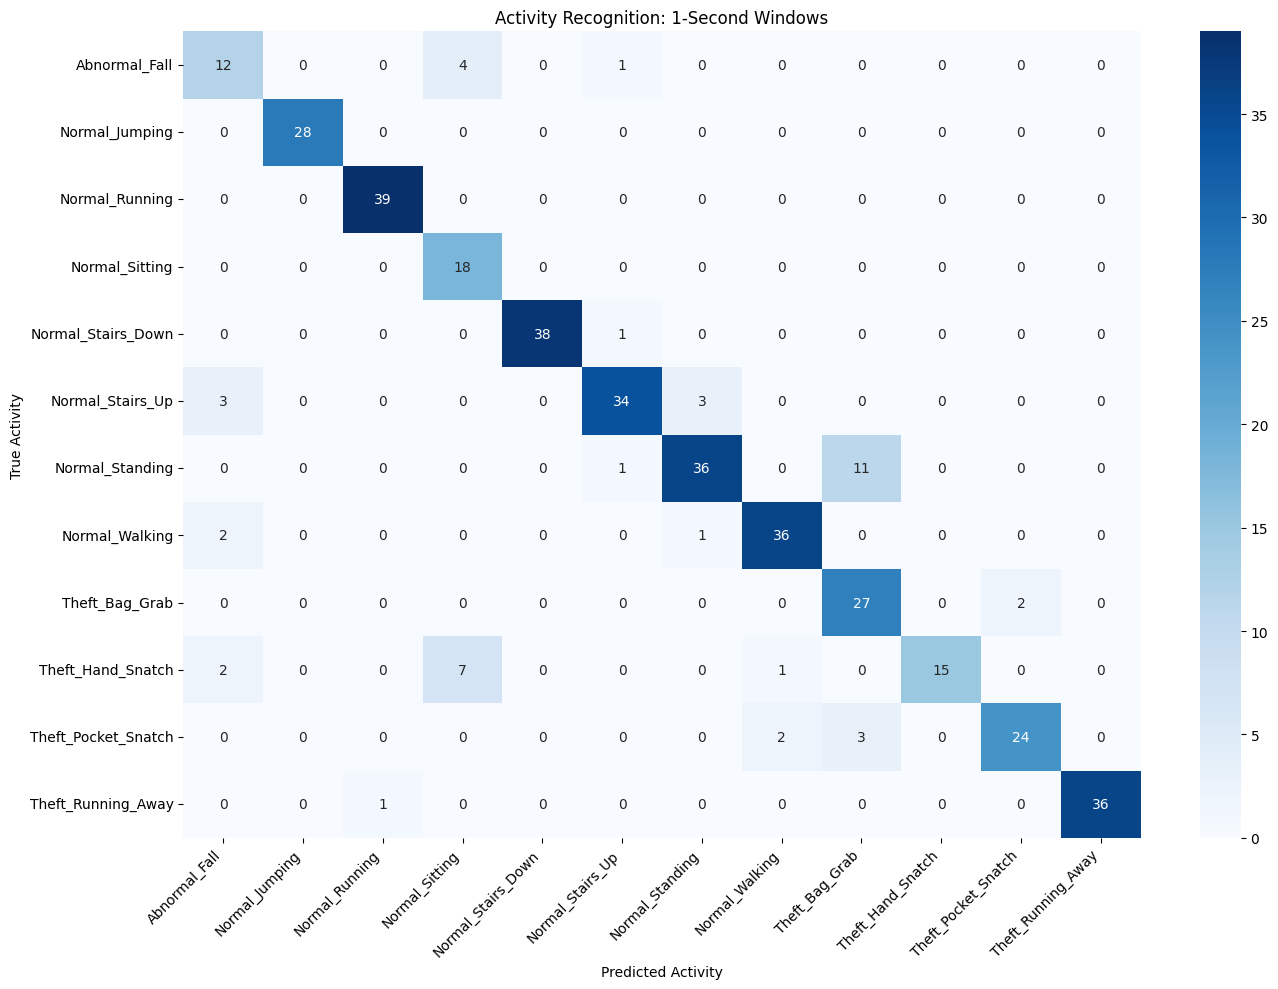

In [8]:
# 1. Get predictions on the new 1-second test windows
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 2. Plot the new confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(14, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)
plt.title('Activity Recognition: 1-Second Windows')
plt.ylabel('True Activity')
plt.xlabel('Predicted Activity')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [9]:
import tensorflow as tf
import json
from google.colab import files

# 1. Convert the Keras model to TFLite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Enable Select TF ops to ensure the LSTM layers are fully supported on mobile
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

tflite_model = converter.convert()

# 2. Save the compressed model
with open('activity_model.tflite', 'wb') as f:
    f.write(tflite_model)

# 3. Export the label mapping to a JSON file
labels_dict = {int(i): str(name) for i, name in enumerate(encoder.classes_)}
with open('labels.json', 'w') as f:
    json.dump(labels_dict, f)

print("Conversion successful. Downloading files...")

# 4. Trigger the download to your local machine
files.download('activity_model.tflite')
files.download('labels.json')

Saved artifact at '/tmp/tmp_f1vqm6d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 50, 6), dtype=tf.float32, name='keras_tensor_7')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  134609708743568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609708734736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707517520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707516560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707516752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707521360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707517712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707522128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707517328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134609707525968: TensorSpec(shape=(), dtype=tf.resource, name=None)
Conversion successf

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>